<a href="https://colab.research.google.com/github/raj241013006122-cyber/raj241013006122tiu/blob/main/Lab6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stroke Prediction: SMOTE and Classifier Comparison

**B.Tech CSE-AIML Lab Exercise**

This notebook:
1. Imports `stroke_processed_5k.csv` (or another processed stroke CSV).
2. Checks and preprocesses the data.
3. Splits the data into training and testing sets.
4. Trains six classifiers on the original training data and on SMOTE-balanced training data.
5. Evaluates both versions on the **same untouched test set**.
6. Displays 12 confusion matrices, comparative metric tables, plots, and the top three SMOTE models.

**Important:** SMOTE is applied only to training data to prevent data leakage. The test set keeps its original class distribution. These are educational predictions, not a clinical diagnostic tool.


## 1. Install required library

In [5]:
%pip -q install imbalanced-learn

## 2. Import libraries

In [6]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from google.colab import files

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")


## 3. Upload and load the CSV dataset

In [7]:
# Run this cell and select stroke_processed_5k.csv from your computer.
uploaded = files.upload()

if not uploaded:
    raise ValueError("No file was uploaded. Please upload your CSV dataset.")

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Loaded file:", file_name)
print("Dataset shape:", df.shape)
display(df.head())


Saving stroke_processed_5k (4).csv to stroke_processed_5k (4) (1).csv
Loaded file: stroke_processed_5k (4) (1).csv
Dataset shape: (5110, 11)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,1.051434,0,1,1,2,1,2.706375,1.005086,1,1
1,0,0.786070,0,0,1,3,0,2.121559,-0.098981,2,1
2,1,1.626390,0,1,1,2,0,-0.005028,0.472536,2,1
3,0,0.255342,0,0,1,2,1,1.437358,0.719327,3,1
4,0,1.582163,1,0,1,3,0,1.501184,-0.631531,2,1


## 4. Inspect and prepare the dataset

Column names:
['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   int64  
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   int64  
 5   work_type          5110 non-null   int64  
 6   Residence_type     5110 non-null   int64  
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                5110 non-null   float64
 9   smoking_status     5110 non-null   int64  
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(8)
memory usage: 439.3 KB
\nMissing value

,Missing values
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,0
smoking_status,0


Target column: stroke
Removed ID columns: []
\nClass distribution in complete dataset:


,Count
stroke,
No stroke (0),4861
Stroke (1),249


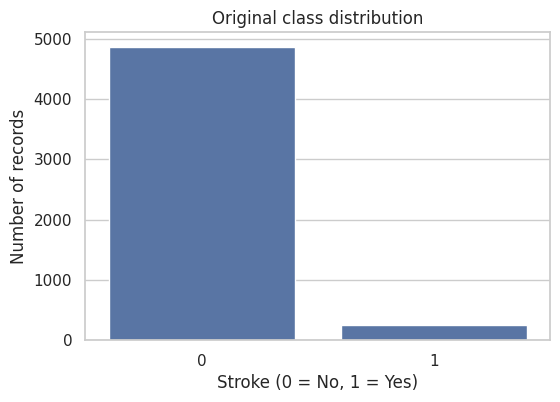

In [8]:
print("Column names:")
print(df.columns.tolist())

print("\\nData types and non-null counts:")
df.info()

print("\\nMissing values per column:")
display(df.isnull().sum().to_frame("Missing values"))

# Find the target column without depending on capitalization or surrounding spaces.
target_candidates = [c for c in df.columns if str(c).strip().lower() == "stroke"]
if not target_candidates:
    raise ValueError(
        "Could not find a target column named 'stroke'. "
        "Rename your target column to 'stroke' and rerun this cell."
    )
TARGET = target_candidates[0]

# Remove rows where the target is missing.
df = df.dropna(subset=[TARGET]).copy()

# Normalize common text labels if the target is stored as text.
if df[TARGET].dtype == "object":
    df[TARGET] = df[TARGET].astype(str).str.strip().str.lower()
    label_map = {
        "no": 0, "no stroke": 0, "negative": 0, "false": 0,
        "yes": 1, "stroke": 1, "positive": 1, "true": 1
    }
    df[TARGET] = df[TARGET].map(label_map).fillna(df[TARGET])

# Convert target to numeric and validate binary classes.
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df.dropna(subset=[TARGET]).copy()
df[TARGET] = df[TARGET].astype(int)

classes = sorted(df[TARGET].unique().tolist())
if len(classes) != 2:
    raise ValueError(f"Expected a binary target with two classes, but found: {classes}")
if classes != [0, 1]:
    raise ValueError(
        f"Expected target labels 0 and 1, but found {classes}. "
        "Please encode no-stroke as 0 and stroke as 1."
    )

# Remove common identifier columns if present (IDs are not useful predictors).
id_columns = [
    c for c in df.columns
    if str(c).strip().lower() in {"id", "patient_id", "patientid"}
]

X = df.drop(columns=[TARGET] + id_columns)
y = df[TARGET]

if X.shape[1] == 0:
    raise ValueError("No feature columns remain after removing the target/ID columns.")

print("Target column:", TARGET)
print("Removed ID columns:", id_columns)
print("\\nClass distribution in complete dataset:")
display(y.value_counts().sort_index().rename(index={0: "No stroke (0)", 1: "Stroke (1)"}).to_frame("Count"))

plt.figure(figsize=(6, 4))
sns.countplot(x=y)
plt.title("Original class distribution")
plt.xlabel("Stroke (0 = No, 1 = Yes)")
plt.ylabel("Number of records")
plt.show()


## 5. Train-test split

In [9]:
# Keep the test set untouched and preserve the original class proportions.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\\nTraining class distribution:")
display(y_train.value_counts().sort_index().to_frame("Count"))
print("\\nTest class distribution (not resampled):")
display(y_test.value_counts().sort_index().to_frame("Count"))


Training rows: 4088
Testing rows: 1022
\nTraining class distribution:


,Count
stroke,
0,3889
1,199


\nTest class distribution (not resampled):


,Count
stroke,
0,972
1,50


## 6. Preprocessing pipeline

In [10]:
# Identify numeric and categorical columns from the training features.
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Dense one-hot output works consistently with SMOTE and the classifiers below.
try:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:  # Compatibility with older scikit-learn versions
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse=False)

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", one_hot)
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: ['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status']
Categorical features: []


## 7. Verify SMOTE balancing on training data

Before SMOTE:


,Count
stroke,
0,3889
1,199


After SMOTE:


,Count
stroke,
0,3889
1,3889


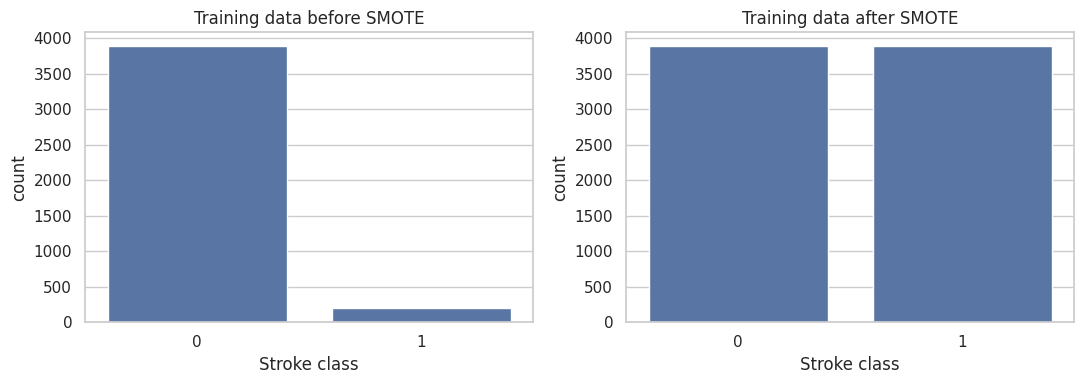

In [11]:
# Fit preprocessing using training data only, then resample the transformed training set.
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

minority_count = y_train.value_counts().min()
if minority_count < 2:
    raise ValueError("SMOTE needs at least two training examples in the minority class.")

smote_preview = SMOTE(random_state=RANDOM_STATE)
X_train_balanced, y_train_balanced = smote_preview.fit_resample(
    X_train_transformed, y_train
)

print("Before SMOTE:")
display(y_train.value_counts().sort_index().to_frame("Count"))

print("After SMOTE:")
display(pd.Series(y_train_balanced).value_counts().sort_index().to_frame("Count"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title("Training data before SMOTE")
axes[0].set_xlabel("Stroke class")
sns.countplot(x=pd.Series(y_train_balanced), ax=axes[1])
axes[1].set_title("Training data after SMOTE")
axes[1].set_xlabel("Stroke class")
plt.tight_layout()
plt.show()


## 8. Define the six classification models

The models are Logistic Regression, Decision Tree, Random Forest, SVM, KNN, and an ANN implemented with scikit-learn's `MLPClassifier`.


In [12]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight=None, random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "SVM": SVC(
        probability=True, random_state=RANDOM_STATE
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),
    "ANN (MLP)": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        max_iter=500,
        early_stopping=True,
        random_state=RANDOM_STATE
    )
}

print("Models to train:")
for model_name in models:
    print("-", model_name)


Models to train:
- Logistic Regression
- Decision Tree
- Random Forest
- SVM
- KNN
- ANN (MLP)


## 9. Train and evaluate original vs SMOTE models

Both versions are evaluated on the same original, untouched test set. The SMOTE pipeline resamples only the training fold inside the pipeline.


In [13]:
results = []
confusion_matrices = {}
classification_reports = {}
fitted_models = {}

for model_name, estimator in models.items():
    print(f"Training {model_name}...")

    # Model trained on the original, imbalanced training data.
    original_pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(estimator))
    ])
    original_pipeline.fit(X_train, y_train)

    # Model trained with SMOTE applied only to the training data.
    smote_pipeline = ImbPipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("classifier", clone(estimator))
    ])
    smote_pipeline.fit(X_train, y_train)

    fitted_models[(model_name, "Original")] = original_pipeline
    fitted_models[(model_name, "SMOTE")] = smote_pipeline

    for dataset_label, fitted_model in [
        ("Original", original_pipeline),
        ("SMOTE", smote_pipeline)
    ]:
        predictions = fitted_model.predict(X_test)

        # All selected classifiers support predict_proba in this notebook.
        probabilities = fitted_model.predict_proba(X_test)[:, 1]

        cm = confusion_matrix(y_test, predictions, labels=[0, 1])
        confusion_matrices[(model_name, dataset_label)] = cm
        classification_reports[(model_name, dataset_label)] = classification_report(
            y_test, predictions, labels=[0, 1],
            target_names=["No stroke", "Stroke"],
            zero_division=0
        )

        results.append({
            "Model": model_name,
            "Dataset": dataset_label,
            "Precision": precision_score(y_test, predictions, zero_division=0),
            "Recall": recall_score(y_test, predictions, zero_division=0),
            "F1-Score": f1_score(y_test, predictions, zero_division=0),
            "Accuracy": accuracy_score(y_test, predictions),
            "AUC-ROC": roc_auc_score(y_test, probabilities)
        })

print("\\nTraining and evaluation completed.")


Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training SVM...
Training KNN...
Training ANN (MLP)...
\nTraining and evaluation completed.


## 10. Final comparative results table

In [14]:
results_df = pd.DataFrame(results)

comparison_table = results_df.sort_values(
    by=["Model", "Dataset"]
).reset_index(drop=True)

display(comparison_table.round(4))

# Pivoted table makes original-versus-SMOTE comparison easier to read.
pivot_table = results_df.pivot(
    index="Model",
    columns="Dataset",
    values=["Precision", "Recall", "F1-Score", "Accuracy", "AUC-ROC"]
)
display(pivot_table.round(4))


,Model,Dataset,Precision,Recall,F1-Score,Accuracy,AUC-ROC
0,ANN (MLP),Original,0.0000,0.00,0.0000,0.9511,0.5410
1,ANN (MLP),SMOTE,0.1333,0.28,0.1806,0.8757,0.7664
2,Decision Tree,Original,0.1667,0.18,0.1731,0.9159,0.5669
3,Decision Tree,SMOTE,0.1184,0.18,0.1429,0.8943,0.5555
4,KNN,Original,0.2000,0.02,0.0364,0.9481,0.6140
5,KNN,SMOTE,0.0884,0.32,0.1385,0.8053,0.6639
6,Logistic Regression,Original,0.0000,0.00,0.0000,0.9511,0.8377
7,Logistic Regression,SMOTE,0.1460,0.80,0.2469,0.7613,0.8381
8,Random Forest,Original,0.0000,0.00,0.0000,0.9481,0.8096
9,Random Forest,SMOTE,0.1579,0.12,0.1364,0.9256,0.7907


Precision           Recall       F1-Score          \
Dataset              Original   SMOTE Original SMOTE Original   SMOTE   
Model                                                                   
ANN (MLP)              0.0000  0.1333     0.00  0.28   0.0000  0.1806   
Decision Tree          0.1667  0.1184     0.18  0.18   0.1731  0.1429   
KNN                    0.2000  0.0884     0.02  0.32   0.0364  0.1385   
Logistic Regression    0.0000  0.1460     0.00  0.80   0.0000  0.2469   
Random Forest          0.0000  0.1579     0.00  0.12   0.0000  0.1364   
SVM                    0.0000  0.1179     0.00  0.58   0.0000  0.1959   

                    Accuracy          AUC-ROC          
Dataset             Original   SMOTE Original   SMOTE  
Model                                                  
ANN (MLP)             0.9511  0.8757   0.5410  0.7664  
Decision Tree         0.9159  0.8943   0.5669  0.5555  
KNN                   0.9481  0.8053   0.6140  0.6639  
Logistic Regression   0.9511  0.7613   0.8377  0.8381  
Random Forest         0.9481  0.9256   0.8096  0.7907  
SVM                   0.9511  0.7671   0.6108  0.7762

## 11. Confusion matrices for all 12 model runs

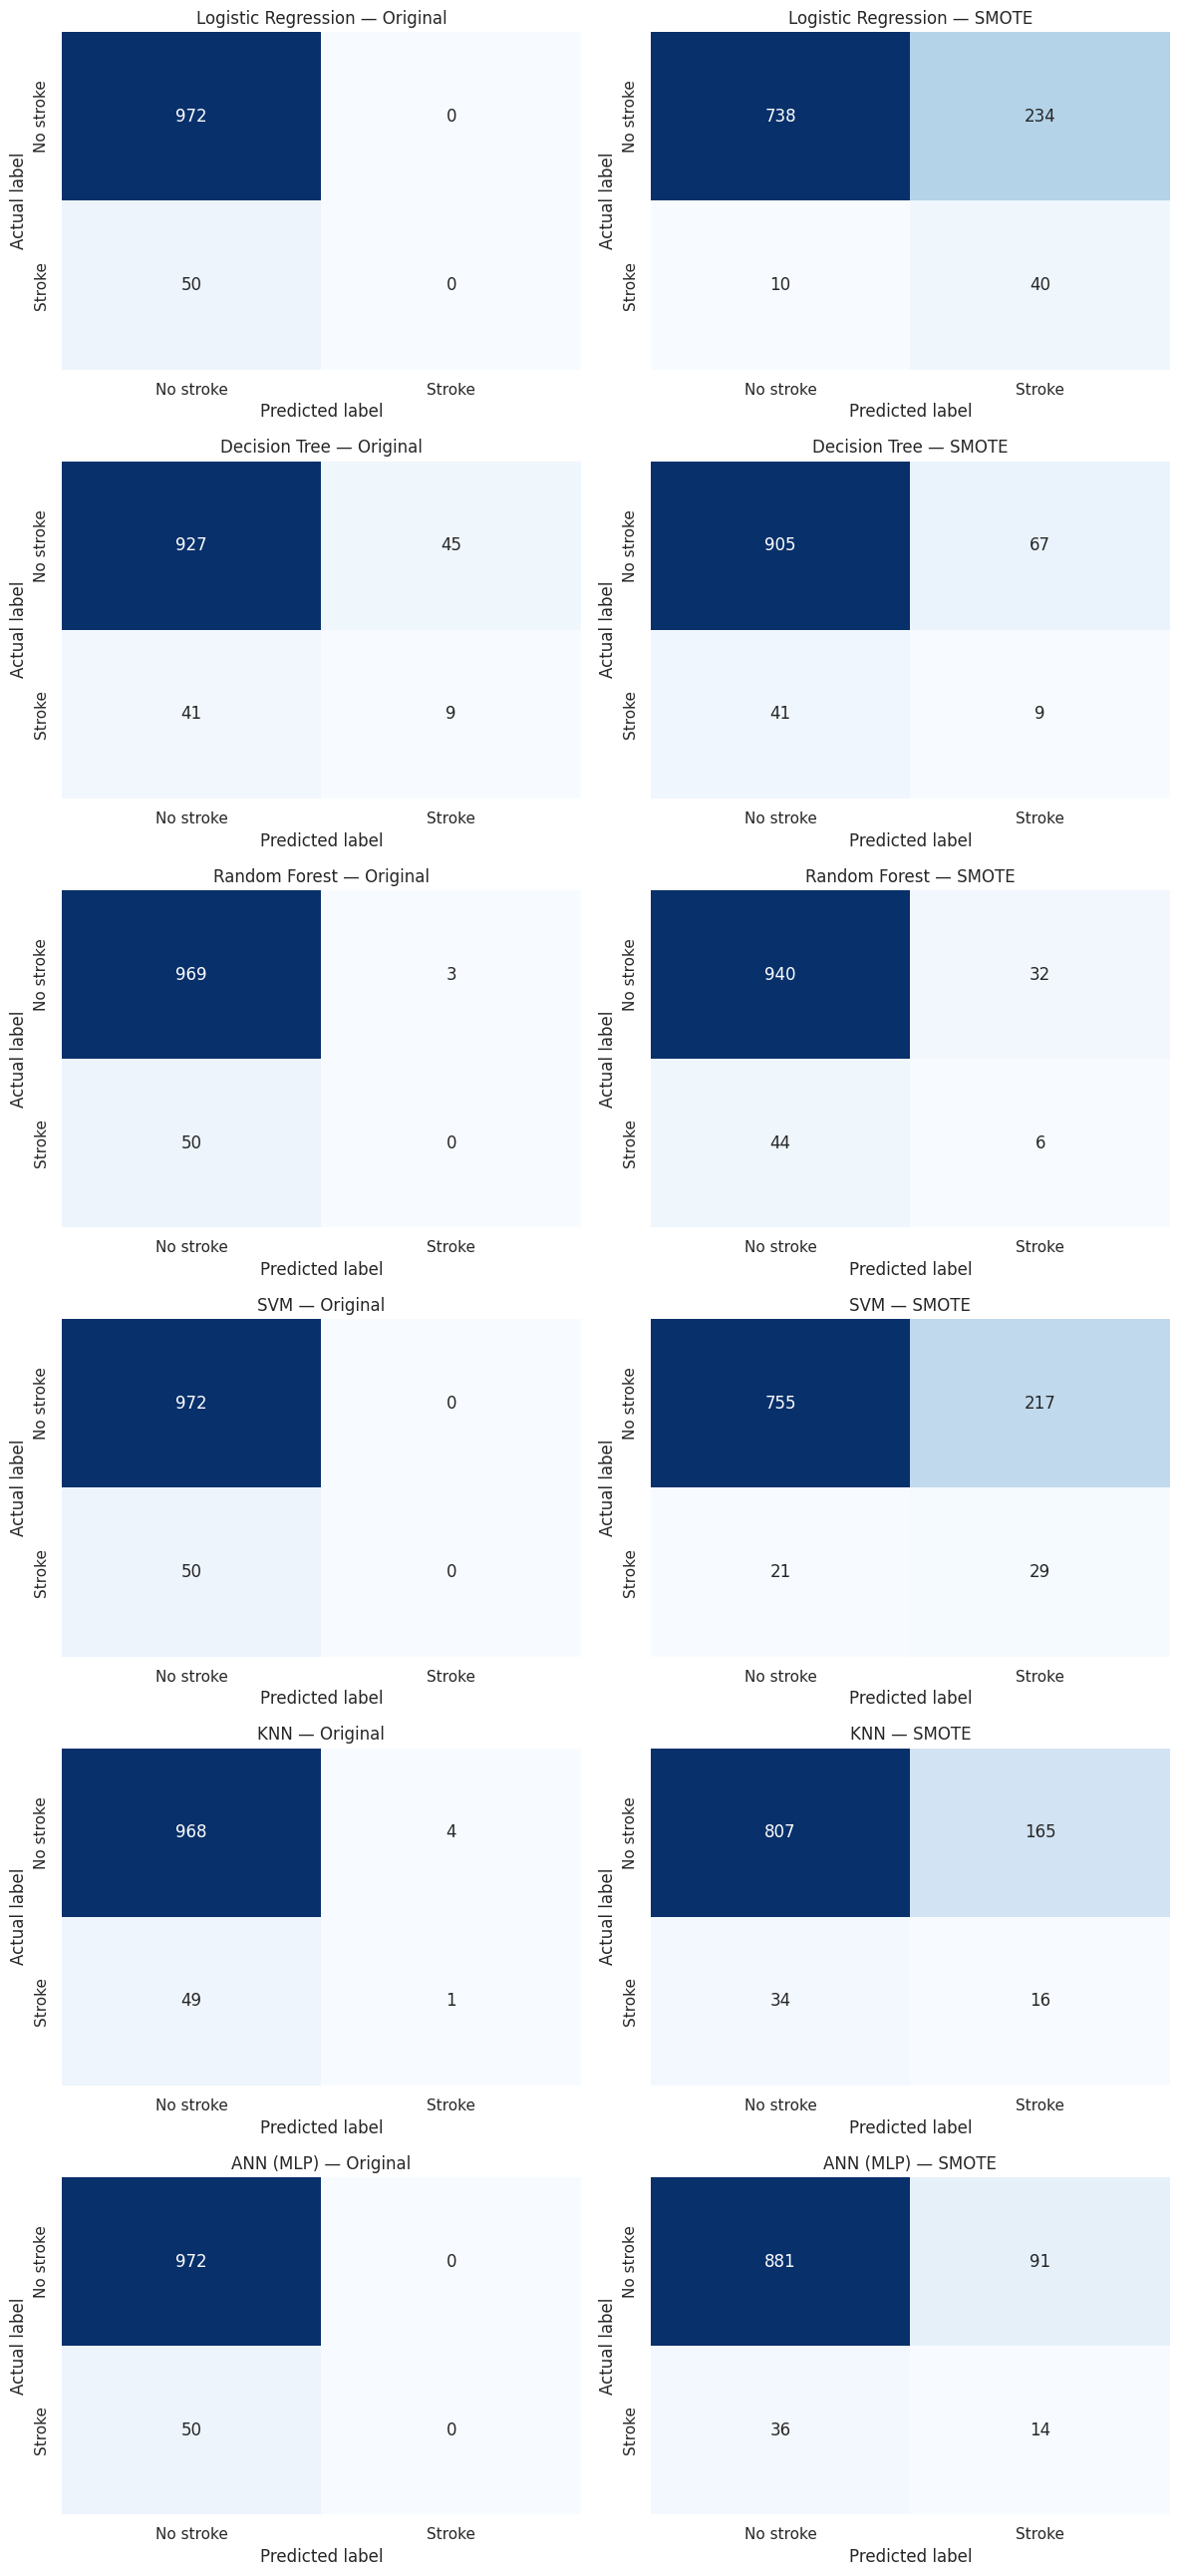

In [15]:
fig, axes = plt.subplots(6, 2, figsize=(12, 26))

for row, model_name in enumerate(models.keys()):
    for col, dataset_label in enumerate(["Original", "SMOTE"]):
        cm = confusion_matrices[(model_name, dataset_label)]
        sns.heatmap(
            cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["No stroke", "Stroke"],
            yticklabels=["No stroke", "Stroke"],
            ax=axes[row, col]
        )
        axes[row, col].set_title(f"{model_name} — {dataset_label}")
        axes[row, col].set_xlabel("Predicted label")
        axes[row, col].set_ylabel("Actual label")

plt.tight_layout()
plt.show()


## 12. Classification reports (optional detailed metrics)

In [16]:
for model_name in models:
    for dataset_label in ["Original", "SMOTE"]:
        print(f"\\n{model_name} — {dataset_label}")
        print(classification_reports[(model_name, dataset_label)])


\nLogistic Regression — Original
              precision    recall  f1-score   support

   No stroke       0.95      1.00      0.97       972
      Stroke       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022

\nLogistic Regression — SMOTE
              precision    recall  f1-score   support

   No stroke       0.99      0.76      0.86       972
      Stroke       0.15      0.80      0.25        50

    accuracy                           0.76      1022
   macro avg       0.57      0.78      0.55      1022
weighted avg       0.95      0.76      0.83      1022

\nDecision Tree — Original
              precision    recall  f1-score   support

   No stroke       0.96      0.95      0.96       972
      Stroke       0.17      0.18      0.17        50

    accuracy                           0.92      1022
   macro avg       0.56      0.57     

## 13. Compare metrics with graphs

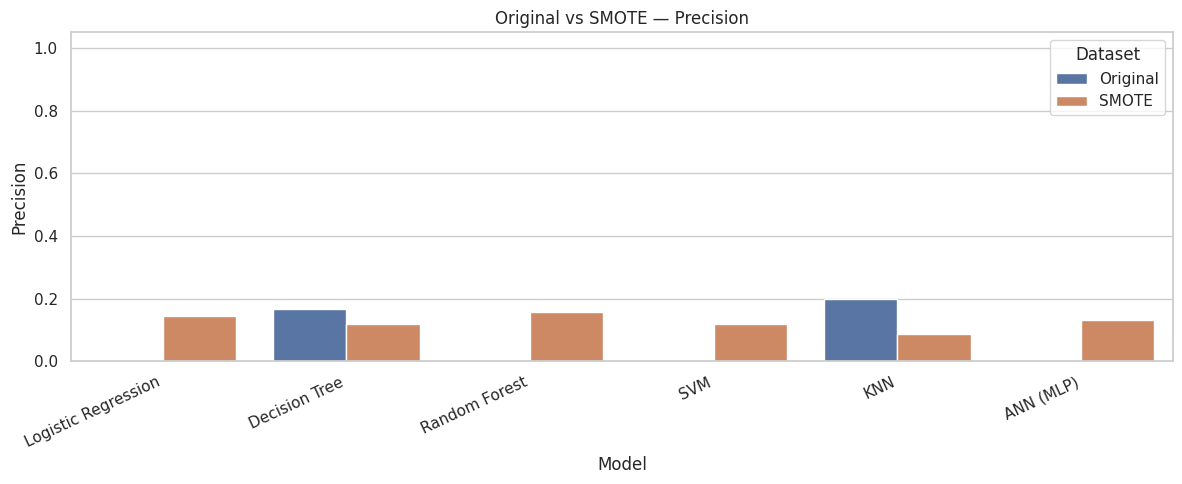

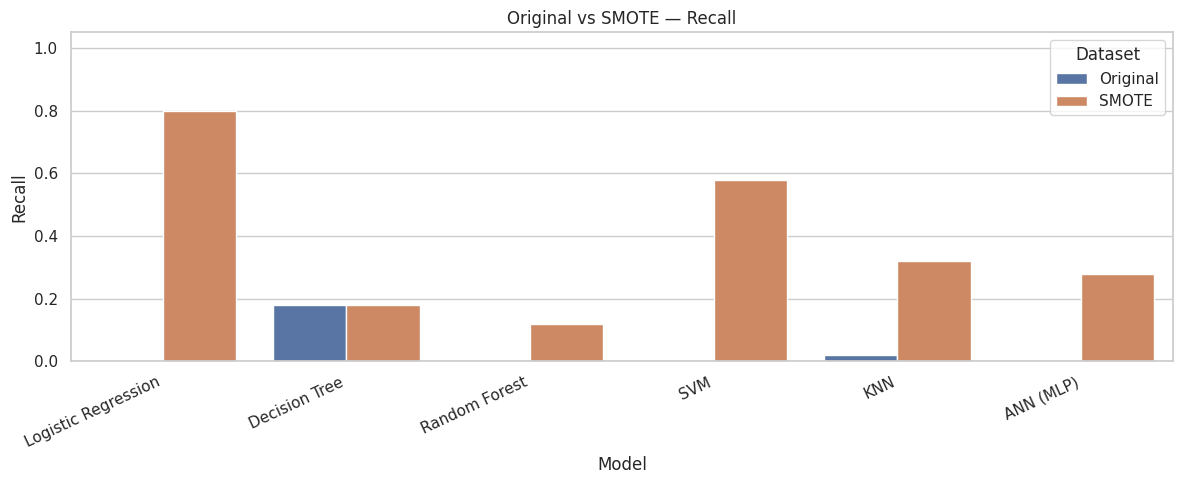

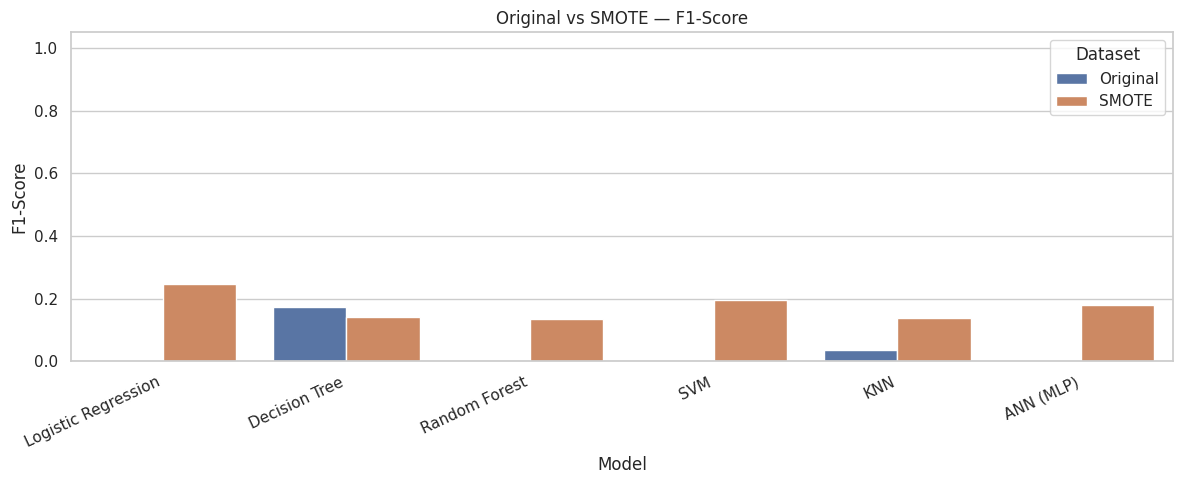

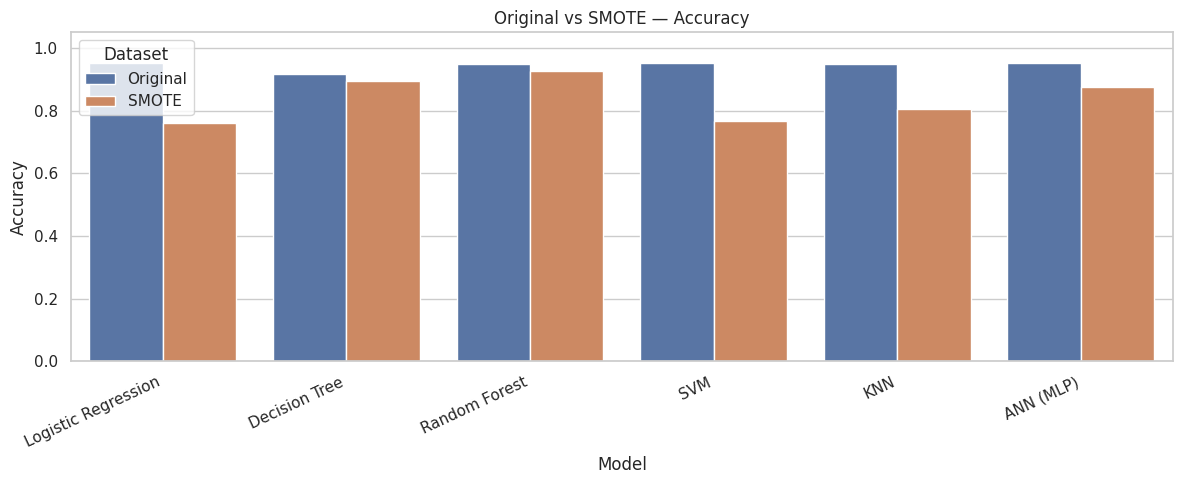

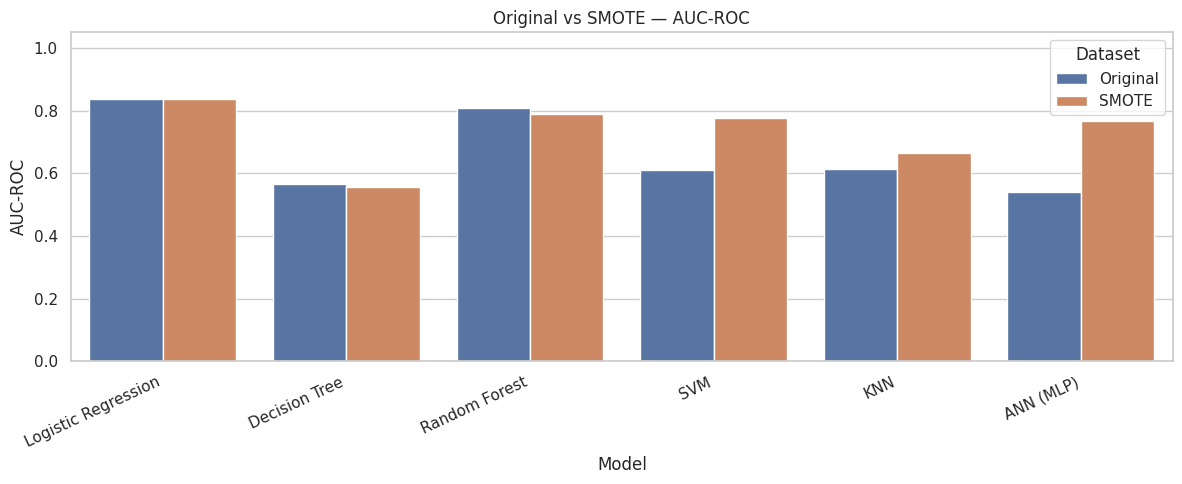

In [17]:
metric_names = ["Precision", "Recall", "F1-Score", "Accuracy", "AUC-ROC"]

for metric in metric_names:
    plt.figure(figsize=(12, 5))
    sns.barplot(
        data=results_df,
        x="Model",
        y=metric,
        hue="Dataset"
    )
    plt.title(f"Original vs SMOTE — {metric}")
    plt.ylim(0, 1.05)
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()


## 14. Identify the top three SMOTE models

The ranking below uses **F1-Score** as the primary criterion. For a stroke-risk task, also inspect recall and AUC-ROC because missing positive cases is important. The best model should not be selected by accuracy alone.


In [18]:
smote_results = results_df[results_df["Dataset"] == "SMOTE"].copy()

top_three = smote_results.sort_values(
    by=["F1-Score", "Recall", "AUC-ROC"],
    ascending=False
).head(3).reset_index(drop=True)

print("TOP THREE MODELS ON THE SMOTE-TRAINED DATA")
display(top_three.round(4))

best_model_name = top_three.loc[0, "Model"]
print("Top-ranked model by F1-Score:", best_model_name)


TOP THREE MODELS ON THE SMOTE-TRAINED DATA


,Model,Dataset,Precision,Recall,F1-Score,Accuracy,AUC-ROC
0,Logistic Regression,SMOTE,0.1460,0.80,0.2469,0.7613,0.8381
1,SVM,SMOTE,0.1179,0.58,0.1959,0.7671,0.7762
2,ANN (MLP),SMOTE,0.1333,0.28,0.1806,0.8757,0.7664


Top-ranked model by F1-Score: Logistic Regression


## 15. Save result tables to CSV

In [19]:
comparison_table.to_csv("stroke_model_comparison.csv", index=False)
top_three.to_csv("stroke_top_three_models.csv", index=False)

print("Saved:")
print("- stroke_model_comparison.csv")
print("- stroke_top_three_models.csv")

files.download("stroke_model_comparison.csv")
files.download("stroke_top_three_models.csv")


Saved:
- stroke_model_comparison.csv
- stroke_top_three_models.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 16. Lab result and conclusion

**Result:** The processed Stroke Dataset was loaded and inspected. The training data was balanced using SMOTE. Six classifiers (Logistic Regression, Decision Tree, Random Forest, SVM, KNN, and ANN/MLP) were trained using both the original and SMOTE-balanced training data. All models were evaluated on the same untouched test set using Precision, Recall, F1-Score, Accuracy, AUC-ROC, and confusion matrices.

**Conclusion:** Compare the generated tables and plots to determine whether SMOTE improved minority-class detection. Report the top three SMOTE models using the actual values printed in Section 14. Do not fill in estimated or invented metric values.

**Note:** SMOTE creates synthetic training examples; it does not prove that a model can diagnose or predict an individual's medical outcome.
